# Exercise 14.3 – Engineered features and model performance
**AWAITING HUMAN REVIEW**. KI-Unterstützung: Codex (Implementierung und technische Prüfung). Studentische Bewertung steht aus.

## 1. Ziel
Die [offizielle Aufgabe 14.3](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/1_self_study_session1.html) verlangt Bäume zunehmender Tiefe für **HDF und PWF**, jeweils ohne und mit **temp_diff beziehungsweise power**. Wir berichten **F1 statt Accuracy** und erklären die Klassenungleichheit. Aufgabenstellung und [Kurskontext 13.1.5/13.1.6.2](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/0_0_predictive_maintenance.html) gelesen am **19.11.2026**. Keine weiteren Fehlertypen oder Aufgabe 14.4.

## 2. Daten und Methode
Unveränderte AI4I-2020-CSV, synthetische Daten aus [UCI](https://doi.org/10.24432/C5HS5C), **CC BY 4.0**. Der vorhandene Loader prüft SHA256, Form 10.000 × 14, Datentypen, fehlende Werte und Duplikate. Der geprüfte Originalbestand ist für Offline-Ausführung im Projekt vorhanden.

Ein Entscheidungsbaum teilt anhand einzelner Merkmalsgrenzen. Physikalisch begründete Merkmale können Zusammenhänge in weniger Schnitten ausdrücken:
- **temp_diff [K] = Prozesstemperatur − Lufttemperatur** für HDF (Wärmeabfuhrfehler).
- **power [W] = Drehmoment [Nm] · Drehzahl [rpm] · 2π/60** für PWF (Leistungsfehler).

Basis sind fünf Messgrößen: Luft-/Prozesstemperatur, Drehzahl, Drehmoment, Werkzeugverschleiß. Pro Ziel kommt nur sein gefordertes Merkmal hinzu; weder IDs, Type noch andere Fehlerflags dienen als Eingaben. Beide Varianten enthalten damit dieselbe ursprüngliche Information; das Zusatzmerkmal ändert ihre Darstellung für den Baum.

Wir verwenden die vorhandene Baumfunktion aus 14.2: Seed **42**, `min_samples_split=5`, `min_samples_leaf=5`; Tiefen **1–8** sind vorgegeben für diesen Vergleich, keine nach TEST optimierte Auswahl. Je Ziel ein fester stratifizierter **80/20-Split**, identisch für alle Tiefen und beide Varianten dieses Ziels. HDF und PWF haben getrennte Ziel-spezifische Splits. Ausschließlich TRAIN beim Fit; zeilenweise feste Formeln ohne gelernte Skalierung. Kein Modell wird aufgrund der TEST-Kurve ausgewählt. Wiederholte Betrachtung derselben TEST-Daten macht sie für spätere Optimierung ungeeignet.

**F1 = 2·TP / (2·TP + FP + FN)**, positive Klasse ist das jeweilige Fehlerflag. TP sind korrekt erkannte Fehler, FP falsche Alarme, FN übersehene Fehler. Ein Modell, das immer „kein Fehler“ meldet, erreicht wegen der seltenen Fehler fast 99 % Accuracy, erkennt aber keinen einzigen Fehler und hat F1 = 0. F1 berücksichtigt diese verfehlten positiven Fälle; richtig negative Fälle gehen nicht ein. Deshalb nennen wir zusätzlich FP und FN, ohne Accuracy als Leistungsmaß zu verwenden.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))
from sessions.ch14.engineered_features import analyze, FEATURES
from sessions.ch10.ai4i_data import verify_file
output = root / "outputs/ch14/exercise_14_3"
output.mkdir(parents=True, exist_ok=True)
data, metrics, predictions, splits, counts = analyze()
print("Originaldaten-SHA256:", verify_file())
display(counts)
metrics.to_csv(output / "f1_comparison.csv", index=False)
predictions.to_csv(output / "depth3_predictions.csv", index=False)
counts.to_csv(output / "class_counts.csv", index=False)
summary = {"rows": len(data), "seed": 42, "depths": list(range(1,9)), "status": "AWAITING HUMAN REVIEW", "class_counts": counts.to_dict(orient="records")}
(output / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8");

Originaldaten-SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


,Ziel,Gesamt,Positive,TRAIN,TRAIN positiv,TEST,TEST positiv
0,HDF,10000,115,8000,92,2000,23
1,PWF,10000,95,8000,76,2000,19


## 3. Ergebnisse: F1 über der Baumtiefe
Durchgezogene Linien zeigen TEST, gestrichelte TRAIN. Die Anpassung auf TRAIN ist kein unabhängiger Nachweis der Modellgüte. Alle Tiefen und beide Varianten nutzen je Ziel denselben Split und dieselben sonstigen Parameter.

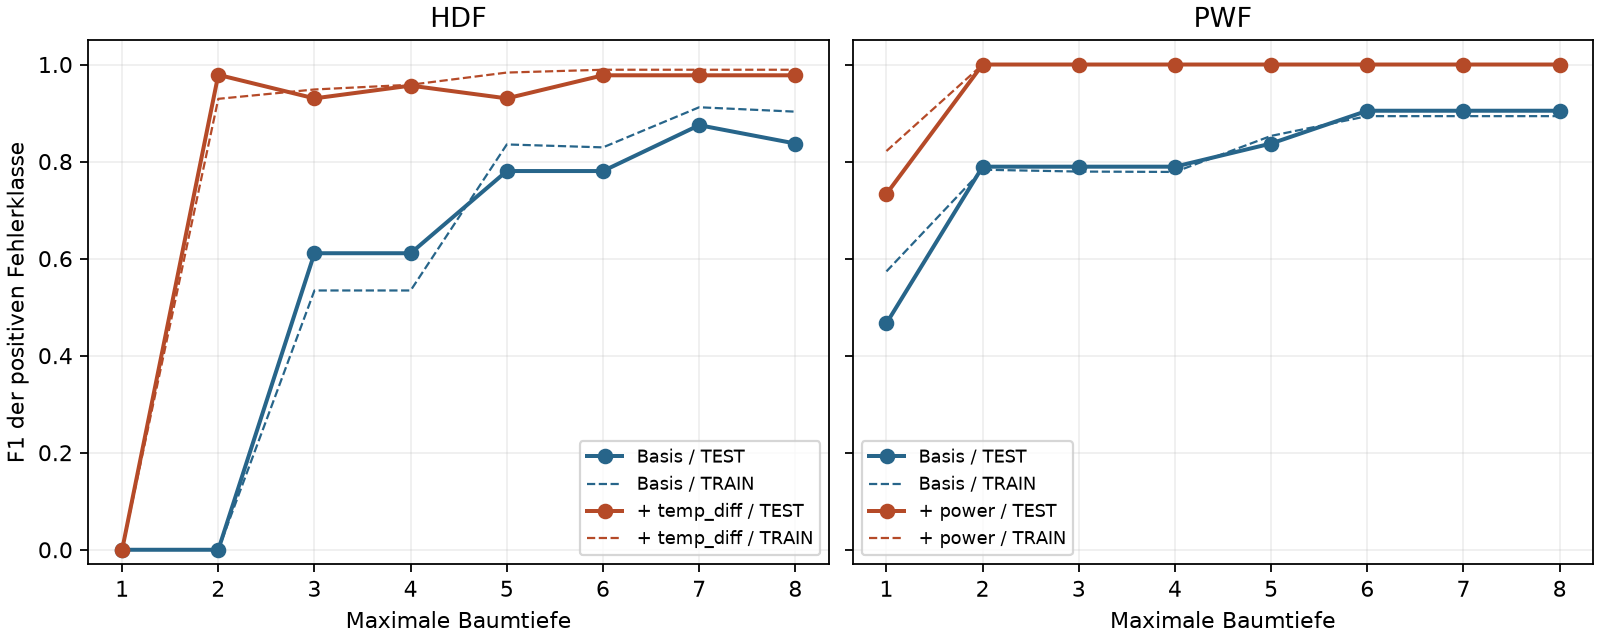

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained", sharey=True)
for ax, (target, feature) in zip(axes, FEATURES.items()):
    for variant, color in [("Basis", "#27658a"), ("+ Merkmal", "#b54a28")]:
        for split, style in [("TEST", "-"), ("TRAIN", "--")]:
            selected = metrics.loc[(metrics.Ziel == target) & (metrics.Variante == variant) & (metrics.Split == split)]
            label = ("Basis" if variant == "Basis" else "+ " + feature) + " / " + split
            ax.plot(selected.Tiefe, selected.F1, style, color=color, marker="o" if split == "TEST" else None, linewidth=1.8 if split == "TEST" else 1, label=label)
    ax.set(title=target, xlabel="Maximale Baumtiefe", xticks=range(1,9), ylim=(-.03,1.05))
    ax.grid(alpha=.2); ax.legend(fontsize=8)
axes[0].set_ylabel("F1 der positiven Fehlerklasse")
fig.savefig(output / "01_f1_depth.png", dpi=160)
plt.close(fig)
display(Image(filename=str(output / "01_f1_depth.png")))

## 4. Kurze Interpretation
Für eine kompakte Zahlentabelle zeigen wir zusätzlich die bereits im Kurs verwendete Tiefe 3. Dies ist **keine Auswahl anhand des besten TEST-Werts**; sämtliche Tiefen stehen in Grafik und CSV.

In [3]:
display(metrics.loc[(metrics.Split == "TEST") & (metrics.Tiefe == 3), ["Ziel", "Variante", "Tiefe", "FP", "FN", "TP", "F1"]].reset_index(drop=True))
for target in FEATURES:
    rows = counts.loc[counts.Ziel == target].iloc[0]
    print(f"{target}: Immer-negativ hätte {int(rows['TEST positiv'])} verfehlte TEST-Fehler und F1=0.")

,Ziel,Variante,Tiefe,FP,FN,TP,F1
0,HDF,Basis,3,2,12,11,0.611111
1,HDF,+ Merkmal,3,0,3,20,0.930233
2,PWF,Basis,3,4,4,15,0.789474
3,PWF,+ Merkmal,3,0,0,19,1.000000


HDF: Immer-negativ hätte 23 verfehlte TEST-Fehler und F1=0.
PWF: Immer-negativ hätte 19 verfehlte TEST-Fehler und F1=0.


Bei Tiefe 3 steigt der TEST-F1 für HDF von **0,6111 auf 0,9302**, für PWF von **0,7895 auf 1,0000**. Für HDF sinken dabei die verfehlten Fehler von 12 auf 3, für PWF von 4 auf 0. Die physikalisch vorgegebenen Zusatzmerkmale erleichtern in diesem Split die Trennung bei geringer Tiefe. Sie fügen keine neue Messinformation hinzu.

Der Effekt ist nicht für jede Tiefe gleich: HDF mit temp_diff erreicht bei Tiefe 2 F1 **0,9787**, bei Tiefe 3 dagegen **0,9302**. Größere Tiefe garantiert also keinen monoton steigenden TEST-F1. Wir wählen daraus keinen „optimalen“ Baum. PWF mit power erreicht hier ab Tiefe 2 F1=1; dies bedeutet nur, dass die 19 positiven und 1.981 negativen TEST-Fälle in diesem Split richtig klassifiziert werden.

## 5. Grenzen
HDF hat nur **115**, PWF **95** positive Fälle unter 10.000 Zeilen; im jeweiligen TEST liegen **23 beziehungsweise 19**. Bereits ein zusätzlicher Fehler verändert F1 sichtbar. Die Daten sind synthetisch, die Fehler durch bekannte Regeln geprägt. Ein einzelner zufälliger Split ohne weitere Seeds, externe Maschinen oder zeitlich spätere Daten belegt keine allgemeine Überlegenheit und keinen kausalen Mechanismus.

F1 allein unterscheidet nicht die Kosten von Fehlalarm und übersehenem Fehler; FP/FN bleiben deshalb sichtbar. Alle Modellvergleiche dienen dieser vorgegebenen Übung, keiner nachträglichen TEST-Optimierung. Es wurden keine zusätzlichen Modelle oder Studien durchgeführt. Originaldaten, frühere Ergebnisse und Reviews bleiben erhalten.

**Reproduktion:** `scripts/uv.cmd run --offline --locked python scripts/build_exercise_14_3.py --check-html`. Notebook und eigenständiges HTML sind die Lesedateien; die Aufgabe verlangt keinen PDF-Export. Status: **AWAITING HUMAN REVIEW**.